In [3]:
from datasets import load_dataset

ds = load_dataset("mediabiasgroup/mbib-base")

linguistic_ds = ds["linguistic_bias"]

print(linguistic_ds)

Dataset({
    features: ['id', 'text', 'label', 'dataset_id'],
    num_rows: 401862
})


In [4]:
linguistic_ds.to_pandas().head()

,id,text,label,dataset_id
0,003-3633,It took four months for reports of Heber s dea...,0,3
1,026-149827-B,questions related to civil rights have been ra...,0,26
2,026-19973-B,to back her assertions coulter refers to examp...,0,26
3,026-78003-B,naarjsana or lord of the dance pose is an asana,0,26
4,026-117975-B,for one it illustrates nietzsche s evolution f...,0,26


## 1.Dataset & Labels

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = linguistic_ds.to_pandas()

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nDataset info:")
df.info()

Dataset shape: (401862, 4)

Columns: ['id', 'text', 'label', 'dataset_id']

Data types:
id            object
text          object
label          int64
dataset_id     int64
dtype: object

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 401862 entries, 0 to 401861
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   id          401862 non-null  object
 1   text        401862 non-null  object
 2   label       401862 non-null  int64 
 3   dataset_id  401862 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 12.3+ MB


,Count,Percentage
label,,
0,200931,50.0
1,200931,50.0


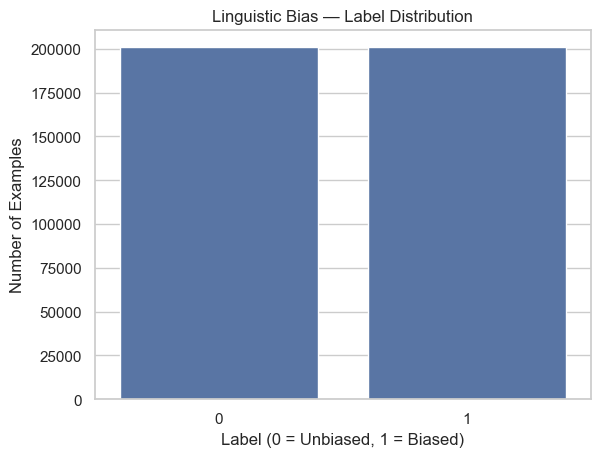

In [6]:
# Label distribution

label_counts = df["label"].value_counts().sort_index()
label_percent = df["label"].value_counts(
    normalize=True
).sort_index() * 100

label_summary = pd.DataFrame({
    "Count": label_counts,
    "Percentage": label_percent.round(2)
})

display(label_summary)

sns.countplot(
    data=df,
    x="label",
    order=[0, 1]
)

plt.title("Linguistic Bias — Label Distribution")
plt.xlabel("Label (0 = Unbiased, 1 = Biased)")
plt.ylabel("Number of Examples")
plt.show()

In [7]:
#Dataset sources

source_summary = pd.crosstab(
    df["dataset_id"],
    df["label"]
)

source_summary.columns = [
    f"Label {col}" for col in source_summary.columns
]

source_summary["Total"] = source_summary.sum(axis=1)

source_summary["Biased %"] = (
    df.groupby("dataset_id")["label"].mean() * 100
).round(2)

display(source_summary.sort_values(
    "Total", ascending=False
))

print("Number of original sources:",
      df["dataset_id"].nunique())

,Label 0,Label 1,Total,Biased %
dataset_id,,,,
26,178228,160833,339061,47.43
35,5842,28731,34573,83.10
3,10068,1662,11730,14.17
75,4894,5960,10854,54.91
10,1862,1618,3480,46.49
9,0,1444,1444,100.00
38,37,683,720,94.86


Number of original sources: 7


### Key Findings — Dataset Sources

- The Linguistic Bias dataset contains **401,862 text samples** collected from **7 source datasets**.
- Dataset 26 dominates the collection, accounting for approximately **84.4%** of all samples.
- Label distributions vary significantly across sources, ranging from **14.17% to 100% biased examples**.
- Dataset 9 contains only biased examples, with no unbiased samples.

**Potential concern:** The strong differences in label distributions between sources may introduce source-related shortcuts. The model could learn source-specific linguistic patterns rather than generalizable indicators of linguistic bias.

**Recommendation:** Investigate source-specific performance and consider group-aware or cross-source evaluation strategies to assess generalization.

In [8]:
# Example inspection
eda_df = df.copy()

eda_df["word_count"] = (
    eda_df["text"].fillna("").str.split().str.len()
)

for label in [0, 1]:
    subset = eda_df[
        (eda_df["label"] == label) &
        (eda_df["word_count"] > 0)
    ].copy()

    subset["length_group"] = pd.qcut(
        subset["word_count"].rank(method="first"),
        q=3,
        labels=["Short", "Medium", "Long"]
    )

    print(f"\nLabel {label}")

    for group in ["Short", "Medium", "Long"]:
        sample = subset[
            subset["length_group"] == group
        ].sample(n=1, random_state=42)

        display(sample[
            ["text", "label", "dataset_id", "word_count"]
        ])


Label 0


,text,label,dataset_id,word_count
161124,because it claims that jews are occupying the ...,0,75,16


,text,label,dataset_id,word_count
161230,mark staniszewski b august 19 1973 in brooklyn...,0,26,25


,text,label,dataset_id,word_count
163186,most muslims have not accepted mirza ghulam ah...,0,26,42



Label 1


,text,label,dataset_id,word_count
362920,some consumer digital cameras do this automati...,1,26,12


,text,label,dataset_id,word_count
362777,bremgarten was in 2013 the first area in europ...,1,26,28


,text,label,dataset_id,word_count
362710,US man accused of illegally exporting guns By...,1,35,153


In [9]:
pd.set_option("display.max_colwidth", None)

examples = eda_df.loc[
    [161124, 161230, 163186, 362920, 362777, 362710],
    ["text", "label", "dataset_id", "word_count"]
]

for idx, row in examples.iterrows():
    print(f"\n{'=' * 70}")
    print(f"Row: {idx}")
    print(f"Label: {row['label']}")
    print(f"Source: {row['dataset_id']}")
    print(f"Words: {row['word_count']}")
    print(f"\nText:\n{row['text']}")


Row: 161124
Label: 0
Source: 75
Words: 16

Text:
because it claims that jews are occupying the united states and conspiring to control the world 

Row: 161230
Label: 0
Source: 26
Words: 25

Text:
mark staniszewski b august 19 1973 in brooklyn ny nicknamed mark stan and judo mark is a brazilian jiu jitsu and judo black belt grappler 

Row: 163186
Label: 0
Source: 26
Words: 42

Text:
most muslims have not accepted mirza ghulam ahmad s claims and some do not consider ahmadis to be muslims at all citing in particular the ahmadiyya view on the finality of prophet muhammad ascension and return of jesus and concept of jihad 

Row: 362920
Label: 1
Source: 26
Words: 12

Text:
some consumer digital cameras do this automatically including the olympus e 1 

Row: 362777
Label: 1
Source: 26
Words: 28

Text:
bremgarten was in 2013 the first area in europe to introduce apartheid laws forbidding refugees applying for asylum to visit public places as the library the church etc 

Row: 362710
Label: 1
So

In [10]:
samples = (
    eda_df.groupby(["dataset_id", "label"], group_keys=False)
    .sample(n=2, random_state=42)
)

for _, row in samples.iterrows():
    print("=" * 70)
    print(f"Source: {row['dataset_id']} | Label: {row['label']}")
    print(f"Text: {row['text']}\n")

Source: 3 | Label: 0
Text: They may have provided support for the vertebrae or perhaps prevented the blood vessels from being crushed if the animal s heavy tail pressed against the ground 

Source: 3 | Label: 0
Text: Before the arrival of Europeans the Aboriginal peoples of Canada used symbolic artwork to denote their allegiance to a particular clan or pantribal sodalities and to show legendary and religious themes 

Source: 3 | Label: 1
Text: Due to the immensely absurd amount of money at their disposal AS Monaco are hated by most with a lot of people believing that it is their financial backing rather than their footballing talents that have gotten them to where they are to this day 

Source: 3 | Label: 1
Text: He was held in the Drancy deportation camp outside of Paris France from where he was then shipped to the Auschwitz concentration camp to be murdered by the Nazis 

Source: 9 | Label: 1
Text: A senior Israeli official said the government was not consulted on the ad and did not 

### Key Findings — Manual Text Inspection

- **Label ambiguity:** Some biased texts appear neutral, while some unbiased texts contain emotionally charged language.
- **Source differences:** Writing styles vary significantly across datasets, from formal news articles to informal conversations.
- **Context dependency:** Some labels cannot be clearly understood without additional context.
- **Potential shortcut learning:** Models may learn source-specific patterns rather than linguistic bias.

**Conclusion:** Linguistic bias detection requires careful label interpretation and source-aware evaluation.

##  2. Text Exploration

In [11]:
# Text length analysis
eda_df["char_count"] = (
    eda_df["text"].fillna("").str.len()
)

eda_df["word_count"] = (
    eda_df["text"].fillna("").str.split().str.len()
)

display(
    eda_df.groupby("label")[
        ["char_count", "word_count"]
    ].describe().round(2)
)

char_count                                                     \
           count    mean     std  min    25%    50%    75%      max   
label                                                                 
0       200931.0  201.35  252.59  3.0  103.0  147.0  211.0  12739.0   
1       200931.0  363.80  496.47  5.0  117.0  173.0  271.0  11285.0   

      word_count                                               
           count   mean    std  min   25%   50%   75%     max  
label                                                          
0       200931.0  34.05  43.41  1.0  17.0  25.0  35.0  2324.0  
1       200931.0  61.90  85.58  1.0  20.0  29.0  45.0  2024.0

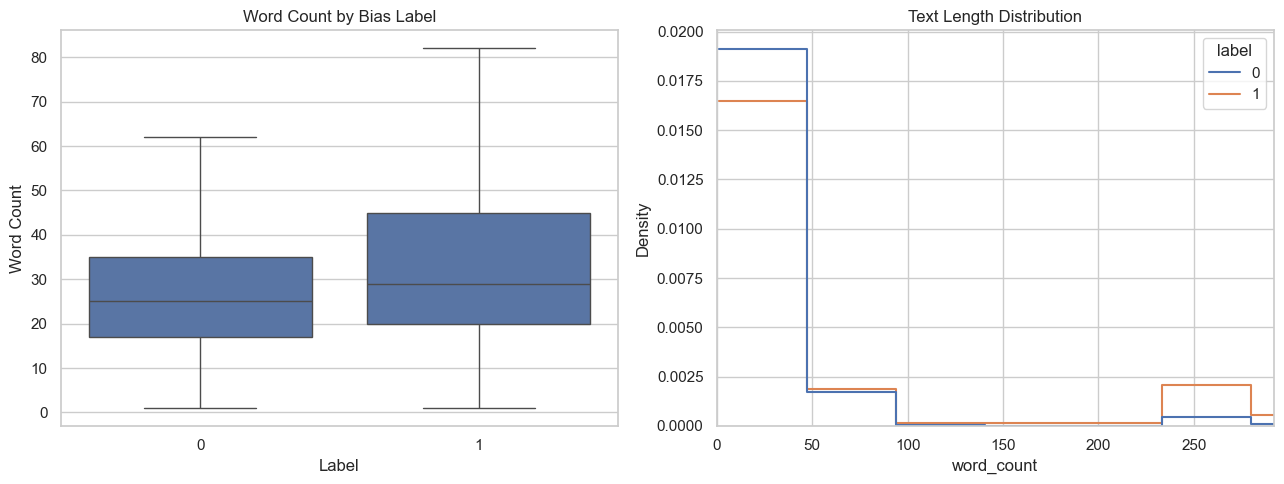

In [12]:
#Compare text lengths
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=eda_df,
    x="label",
    y="word_count",
    showfliers=False,
    ax=axes[0]
)

axes[0].set_title("Word Count by Bias Label")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Word Count")

sns.histplot(
    data=eda_df,
    x="word_count",
    hue="label",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    ax=axes[1]
)

axes[1].set_xlim(
    0, eda_df["word_count"].quantile(0.99)
)
axes[1].set_title("Text Length Distribution")

plt.tight_layout()
plt.show()

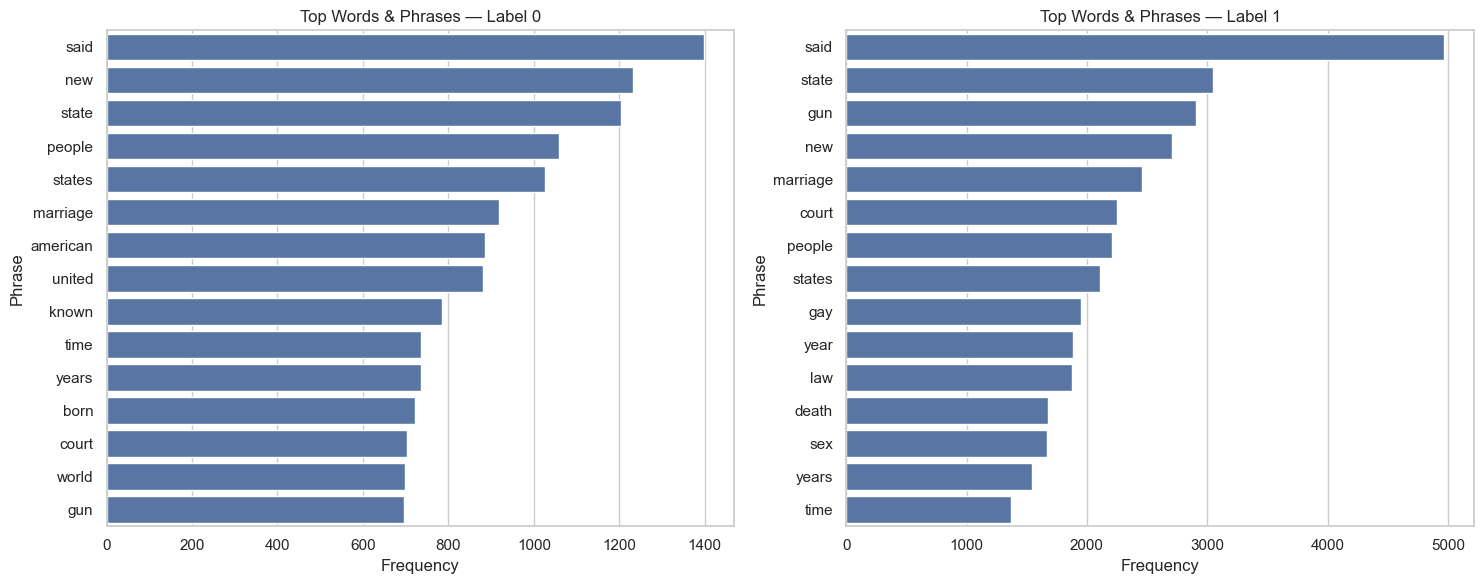

In [13]:
# Common words and phrases
from sklearn.feature_extraction.text import CountVectorizer

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, label in zip(axes, [0, 1]):
    texts = eda_df.loc[
        eda_df["label"] == label, "text"
    ].dropna()

    sample_size = min(20000, len(texts))
    texts = texts.sample(
        n=sample_size, random_state=42
    )

    vectorizer = CountVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        max_features=5000,
        min_df=2
    )

    X = vectorizer.fit_transform(texts)

    frequencies = np.asarray(
        X.sum(axis=0)
    ).ravel()

    top_words = pd.DataFrame({
        "Phrase": vectorizer.get_feature_names_out(),
        "Frequency": frequencies
    }).nlargest(15, "Frequency")

    sns.barplot(
        data=top_words,
        y="Phrase",
        x="Frequency",
        ax=ax
    )

    ax.set_title(f"Top Words & Phrases — Label {label}")

plt.tight_layout()
plt.show()

label,0,1
has_url,0.0,0.0
has_mention,0.0,0.0
has_hashtag,0.0,0.0
has_exclamation,0.0,0.0
has_question,0.0,0.0
has_non_ascii,0.0,0.0


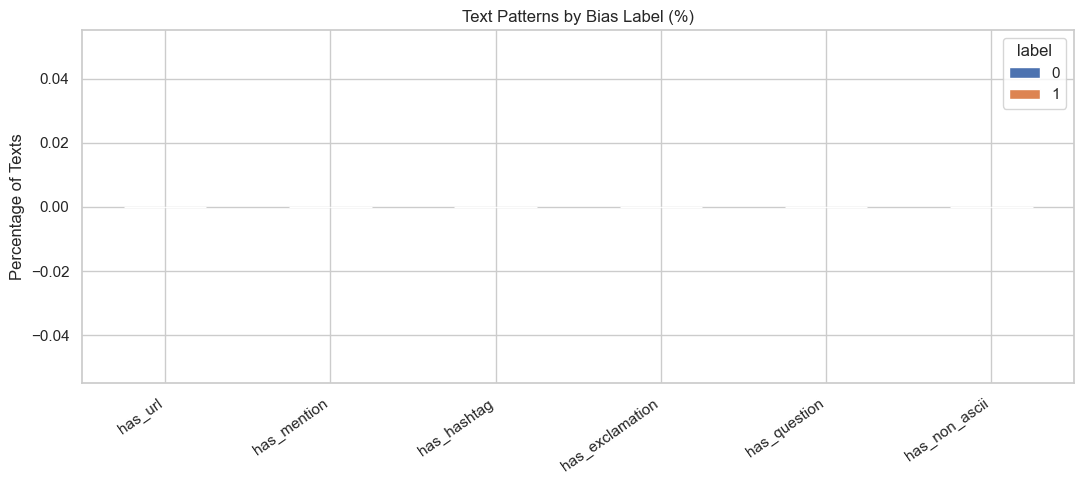

In [14]:
# Punctuation, URLs and unusual patterns
texts = eda_df["text"].fillna("")

eda_df["has_url"] = texts.str.contains(
    r"https?://|www\.", case=False, regex=True
)

eda_df["has_mention"] = texts.str.contains(
    r"@\w+", regex=True
)

eda_df["has_hashtag"] = texts.str.contains(
    r"#\w+", regex=True
)

eda_df["has_exclamation"] = texts.str.contains(
    "!", regex=False
)

eda_df["has_question"] = texts.str.contains(
    "?", regex=False
)

eda_df["has_non_ascii"] = texts.apply(
    lambda x: not x.isascii()
)

pattern_cols = [
    "has_url",
    "has_mention",
    "has_hashtag",
    "has_exclamation",
    "has_question",
    "has_non_ascii"
]

pattern_summary = (
    eda_df.groupby("label")[pattern_cols]
    .mean()
    .mul(100)
    .round(2)
)

display(pattern_summary.T)

pattern_summary.T.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Text Patterns by Bias Label (%)")
plt.ylabel("Percentage of Texts")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [15]:
# Inspect potentially difficult examples
short_examples = eda_df[
    eda_df["word_count"].between(1, 4)
]

print("Very short texts:", len(short_examples))

display(
    short_examples[
        ["text", "label", "dataset_id", "word_count"]
    ].sample(
        n=min(10, len(short_examples)),
        random_state=42
    )
)

Very short texts: 1328


,text,label,dataset_id,word_count
356236,astroturfing fines,1,26,2
30411,sohrabuddin sheikh fake encounter,0,26,4
272441,tyrannicide attempt by panagoulis,1,26,4
46374,support for irish republicanism,0,26,4
17142,title rebbe of bobov,0,26,4
155973,explanation on ibm developerworks,0,26,4
180349,is kraybill s biased,0,26,4
121002,discussion over the holodomor,0,26,4
90168,20042007 liberation,0,26,2
136840,shirley phelps roper activist,0,26,4


## 4. Data Quality

In [16]:
# Missing and empty values

missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": (
        df.isna().mean() * 100
    ).round(2)
})

display(missing_summary)

empty_texts = (
    df["text"].fillna("").str.strip() == ""
).sum()

invalid_labels = (
    ~df["label"].isin([0, 1])
).sum()

print("Empty or whitespace-only texts:", empty_texts)
print("Invalid or missing labels:", invalid_labels)

,Missing Count,Missing %
id,0,0.0
text,0,0.0
label,0,0.0
dataset_id,0,0.0


Empty or whitespace-only texts: 0
Invalid or missing labels: 0


In [17]:
# Exact duplicates and conflicting labels

valid_text = df["text"].notna()

exact_duplicates = df.loc[
    valid_text, "text"
].duplicated().sum()

duplicate_ids = df["id"].duplicated().sum()

label_conflicts = (
    df.loc[valid_text]
    .groupby("text")["label"]
    .nunique()
)

conflicting_texts = (
    label_conflicts > 1
).sum()

print("Duplicate text rows:", exact_duplicates)
print("Duplicate IDs:", duplicate_ids)
print("Texts with conflicting labels:", conflicting_texts)

Duplicate text rows: 0
Duplicate IDs: 5969
Texts with conflicting labels: 0


In [18]:
# Check duplicate IDs within the same source
duplicate_source_ids = df.duplicated(
    subset=["dataset_id", "id"]
).sum()

print("Duplicate IDs across all sources:", duplicate_ids)
print("Duplicate IDs within the same source:", duplicate_source_ids)

Duplicate IDs across all sources: 5969
Duplicate IDs within the same source: 5969


In [19]:
# Identify repeated IDs within each dataset
repeated = df[
    df.duplicated(subset=["dataset_id", "id"], keep=False)
]

print("Repeated IDs by source:")
display(repeated.groupby("dataset_id").size())

print("\nExamples:")
display(
    repeated[
        ["dataset_id", "id", "text", "label"]
    ].head(10)
)

Repeated IDs by source:


dataset_id
75    9066
dtype: int64


Examples:


,dataset_id,id,text,label
48,75,075-2103,gt where did you get the idea that blacks are disproportionately violent that is nowhere in the data huh is this a joke look at murder rates,0
73,75,075-38,a white marxist art hoe girl is all ive ever wanted to be,0
128,75,075-692,looks like an item card art the lady is a statue,0
148,75,075-822,you put in quotations black people are criminals right i did not say that that isnt how quotations work lol you arent very bright,0
152,75,075-558,this is a terrible talking point black people are more likely to live in black communities of course black on black crime rates are higher,0
204,75,075-837,le black people are all criminals amirite,0
213,75,075-753,so youre assuming cig is anti semetic because jews are frugal the irony is strong,0
252,75,075-14,americans are all selfish black are all criminals jews are all greedy etc etc whats your point here racial stereotypes,0
296,75,075-329,do you think all murican muslims are terrorist sympathizers,0
314,75,075-3158,imagined if people cared about loving thy neighbor as much as they care about how sinful gay people are,0


In [20]:
# Analyze repeated IDs in Source 75

source_75 = df[df["dataset_id"] == 75]

id_analysis = source_75.groupby("id").agg(
    text_count=("text", "size"),
    unique_labels=("label", "nunique")
)

print("Unique IDs:", len(id_analysis))
print("IDs appearing more than once:",
      (id_analysis["text_count"] > 1).sum())

print("Repeated IDs with different labels:",
      ((id_analysis["text_count"] > 1) &
       (id_analysis["unique_labels"] > 1)).sum())

print("Maximum texts per ID:",
      id_analysis["text_count"].max())

display(
    id_analysis.sort_values(
        "text_count", ascending=False
    ).head(10)
)

Unique IDs: 4885
IDs appearing more than once: 3097
Repeated IDs with different labels: 2157
Maximum texts per ID: 5


,text_count,unique_labels
id,,
075-1217,5,2
075-2439,5,2
075-1281,5,1
075-1280,5,2
075-77,5,2
075-30,5,2
075-1347,5,2
075-1257,5,2
075-2424,5,2


**Repeated IDs:** Source 75 contains repeated IDs associated with different text samples and labels. This is not necessarily a data quality issue. The meaning of these IDs should be verified before splitting the dataset.

In [21]:
#Near duplicates
normalized_text = (
    df["text"]
    .fillna("")
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

near_duplicate_count = normalized_text.duplicated().sum()

print(
    "Duplicates after case/whitespace normalization:",
    near_duplicate_count
)

Duplicates after case/whitespace normalization: 787


In [22]:
normalized_analysis = df.assign(
    normalized_text=normalized_text
).groupby("normalized_text").agg(
    count=("label", "size"),
    unique_labels=("label", "nunique"),
    unique_sources=("dataset_id", "nunique")
)

duplicates_summary = normalized_analysis[
    normalized_analysis["count"] > 1
]

print("Repeated normalized texts:", len(duplicates_summary))

print(
    "Repeated texts with conflicting labels:",
    (duplicates_summary["unique_labels"] > 1).sum()
)

print(
    "Repeated texts across different sources:",
    (duplicates_summary["unique_sources"] > 1).sum()
)

Repeated normalized texts: 787
Repeated texts with conflicting labels: 418
Repeated texts across different sources: 737


In [23]:
conflicting_groups = duplicates_summary[
    duplicates_summary["unique_labels"] > 1
].head(5).index

display(
    df.assign(normalized_text=normalized_text)
      .loc[
          lambda x: x["normalized_text"].isin(conflicting_groups),
          ["dataset_id", "text", "label", "normalized_text"]
      ]
      .sort_values("normalized_text")
)

,dataset_id,text,label,normalized_text
65997,3,04cv2688 was the first direct challenge brought in United States federal courts against a public school district that required the reference to Intelligent Design as an alternative to evolution as an explanation of the origin of life,0,04cv2688 was the first direct challenge brought in united states federal courts against a public school district that required the reference to intelligent design as an alternative to evolution as an explanation of the origin of life
349274,26,04cv2688 was the first direct challenge brought in united states federal courts against a public school district that required the reference to intelligent design as an alternative to evolution as an explanation of the origin of life,1,04cv2688 was the first direct challenge brought in united states federal courts against a public school district that required the reference to intelligent design as an alternative to evolution as an explanation of the origin of life
124103,3,2010 also saw the spawning of an American based left wing publication Jacobin magazine,0,2010 also saw the spawning of an american based left wing publication jacobin magazine
379053,26,2010 also saw the spawning of an american based left wing publication jacobin magazine,1,2010 also saw the spawning of an american based left wing publication jacobin magazine
90221,3,A beautiful example of a current propelled ferry is in Basel in Switzerland,0,a beautiful example of a current propelled ferry is in basel in switzerland
203573,26,a beautiful example of a current propelled ferry is in basel in switzerland,1,a beautiful example of a current propelled ferry is in basel in switzerland
114550,3,A certificate provider will issue a Domain Validation DV class certificate to a purchaser if the purchaser can demonstrate one straightforward vetting criterion the right to administratively manage the domain name in question,0,a certificate provider will issue a domain validation dv class certificate to a purchaser if the purchaser can demonstrate one straightforward vetting criterion the right to administratively manage the domain name in question
205951,26,a certificate provider will issue a domain validation dv class certificate to a purchaser if the purchaser can demonstrate one straightforward vetting criterion the right to administratively manage the domain name in question,1,a certificate provider will issue a domain validation dv class certificate to a purchaser if the purchaser can demonstrate one straightforward vetting criterion the right to administratively manage the domain name in question
58952,3,A detailed analysis of the Genesis of Castes in India was presented by Dr Babasaheb Ambedkar in his doctoral paper at the Columbia Univerity,0,a detailed analysis of the genesis of castes in india was presented by dr babasaheb ambedkar in his doctoral paper at the columbia univerity
394390,26,a detailed analysis of the genesis of castes in india was presented by dr babasaheb ambedkar in his doctoral paper at the columbia univerity,1,a detailed analysis of the genesis of castes in india was presented by dr babasaheb ambedkar in his doctoral paper at the columbia univerity


In [24]:
conflicting_df = df.assign(
    normalized_text=normalized_text
)

conflicting_df = conflicting_df[
    conflicting_df["normalized_text"].isin(
        duplicates_summary[
            duplicates_summary["unique_labels"] > 1
        ].index
    )
]

conflict_summary = conflicting_df.groupby(
    "normalized_text"
).agg(
    n_sources=("dataset_id", "nunique"),
    n_labels=("label", "nunique")
)

print(
    "Conflicts across multiple sources:",
    (conflict_summary["n_sources"] > 1).sum()
)

print(
    "Conflicts within the same source:",
    conflicting_df.groupby(
        ["dataset_id", "normalized_text"]
    )["label"].nunique().gt(1).sum()
)

Conflicts across multiple sources: 408
Conflicts within the same source: 10


In [25]:
conflicting_texts = duplicates_summary[
    duplicates_summary["unique_labels"] > 1
].index

conflicts = df.assign(
    normalized_text=normalized_text
)

conflicts = conflicts[
    conflicts["normalized_text"].isin(conflicting_texts)
]

source_pairs = (
    conflicts.groupby("normalized_text")["dataset_id"]
    .apply(lambda x: tuple(sorted(x.unique())))
    .value_counts()
)

display(source_pairs)

dataset_id
(3, 26)    408
(26,)       10
Name: count, dtype: int64

In [26]:
# Work on a copy — keep the original dataset unchanged
clean_df = df.copy()

# Normalize text for duplicate detection
clean_df["normalized_text"] = (
    clean_df["text"]
    .fillna("")
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# 1. Identify texts with conflicting labels
label_counts = (
    clean_df.groupby("normalized_text")["label"]
    .nunique()
)

conflicting_keys = label_counts[
    label_counts > 1
].index

# 2. Remove all rows belonging to conflicting groups
conflict_mask = clean_df["normalized_text"].isin(
    conflicting_keys
)

removed_conflicts = int(conflict_mask.sum())

clean_df = clean_df.loc[~conflict_mask].copy()

# 3. Remove duplicate texts with consistent labels
before_dedup = len(clean_df)

clean_df = clean_df.drop_duplicates(
    subset=["normalized_text"],
    keep="first"
).copy()

removed_duplicates = before_dedup - len(clean_df)

# 4. Report results
print("Original rows:", len(df))
print("Rows removed due to label conflicts:", removed_conflicts)
print("Consistent duplicate rows removed:", removed_duplicates)
print("Cleaned rows:", len(clean_df))
print("Total rows removed:", len(df) - len(clean_df))

# Validate remaining labels and duplicates
assert not clean_df["normalized_text"].duplicated().any()
assert clean_df["label"].isin([0, 1]).all()

Original rows: 401862
Rows removed due to label conflicts: 836
Consistent duplicate rows removed: 369
Cleaned rows: 400657
Total rows removed: 1205


### Data Cleaning — Duplicate Handling

- Removed all text samples belonging to groups with conflicting labels.
- Retained one representative sample for each group of normalized duplicate texts with consistent labels.
- Preserved the original dataset for reproducibility.
- Documented all removed records and their removal reasons.

**Rationale:** Reduce contradictory supervision and exact-text duplication before model training.

In [27]:
#Extreme lengths and encoding problems
quality_summary = {
    "Empty texts": int(empty_texts),
    "Texts under 5 words": int(
        (eda_df["word_count"] < 5).sum()
    ),
    "Texts over 500 words": int(
        (eda_df["word_count"] > 500).sum()
    ),
    "Texts with replacement character": int(
        texts.str.contains("\ufffd", regex=False).sum()
    ),
    "Texts with null characters": int(
        texts.str.contains("\x00", regex=False).sum()
    )
}

display(pd.Series(
    quality_summary,
    name="Count"
).to_frame())

,Count
Empty texts,0
Texts under 5 words,1328
Texts over 500 words,219
Texts with replacement character,0
Texts with null characters,0


In [28]:
# Potential privacy indicators
privacy_indicators = pd.DataFrame({
    "Email-like": texts.str.contains(
        r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b",
        regex=True
    ),
    "Phone-like": texts.str.contains(
        r"\+?\d[\d\s().-]{7,}\d",
        regex=True
    ),
    "URL": eda_df["has_url"]
})

display(
    privacy_indicators.sum().to_frame(
        name="Potential Matches"
    )
)

,Potential Matches
Email-like,0
Phone-like,4646
URL,0


## 5. Problem & Domain Understanding

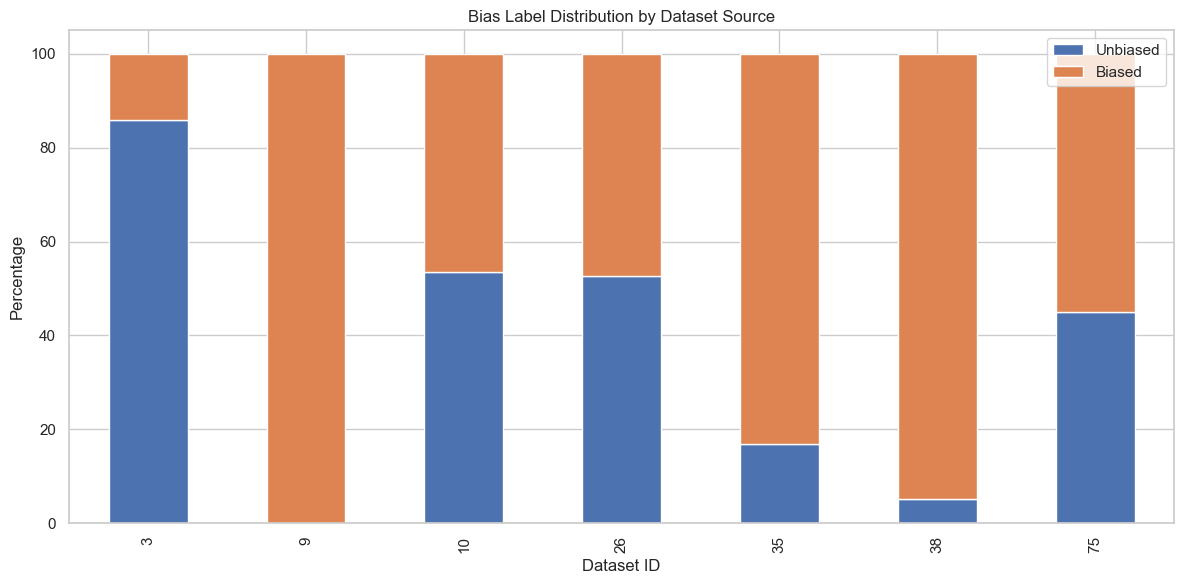

In [29]:
#Source and label relationship
source_label_dist = pd.crosstab(
    df["dataset_id"],
    df["label"],
    normalize="index"
) * 100

source_label_dist.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Bias Label Distribution by Dataset Source")
plt.xlabel("Dataset ID")
plt.ylabel("Percentage")
plt.legend(["Unbiased", "Biased"])
plt.tight_layout()
plt.show()

In [32]:
# Check whether sources can reveal the label
source_stats = df.groupby("dataset_id").agg(
    total=("label", "size"),
    biased_count=("label", "sum"),
    biased_rate=("label", "mean")
)

source_stats["biased_rate"] *= 100

display(
    source_stats.sort_values(
        "biased_rate", ascending=False
    ).round(2)
)

,total,biased_count,biased_rate
dataset_id,,,
9,1444,1444,100.00
38,720,683,94.86
35,34573,28731,83.10
75,10854,5960,54.91
26,339061,160833,47.43
10,3480,1618,46.49
3,11730,1662,14.17


## 6. End-of-Day Checkpoint

In [33]:
checkpoint = pd.Series({
    "Total examples": len(df),
    "Unique sources": df["dataset_id"].nunique(),
    "Unbiased examples": (df["label"] == 0).sum(),
    "Biased examples": (df["label"] == 1).sum(),
    "Biased percentage": round(
        (df["label"] == 1).mean() * 100, 2
    ),
    "Missing texts": df["text"].isna().sum(),
    "Empty texts": empty_texts,
    "Exact duplicate texts": exact_duplicates,
    "Conflicting-label texts": conflicting_texts,
    "Median word count": eda_df["word_count"].median(),
    "Potential encoding issues": quality_summary[
        "Texts with replacement character"
    ]
})

display(checkpoint.to_frame("Result"))

,Result
Total examples,401862
Unique sources,7
Unbiased examples,200931
Biased examples,200931
Biased percentage,50.0
Missing texts,0
Empty texts,0
Exact duplicate texts,0
Conflicting-label texts,"Index(['04cv2688 was the first direct challenge brought in united states federal courts against a public school district that required the reference to intelligent design as an alternative to evolution as an explanation of the origin of life', '2010 also saw the spawning of an american based left wing publication jacobin magazine', 'a beautiful example of a current propelled ferry is in basel in switzerland', 'a certificate provider will issue a domain validation dv class certificate to a purchaser if the purchaser can demonstrate one straightforward vetting criterion the right to administratively manage the domain name in question', 'a detailed analysis of the genesis of castes in india was presented by dr babasaheb ambedkar in his doctoral paper at the columbia univerity', 'a developed country portugal is a member of the european union since 1986 the united nations since 1955 and a founding member of the eurozone oecd and nato', 'a gnu linux distribution is a member of the family of unix like operating systems built on top of the linux kernel', 'a gnu linux distribution often referred to as a linux distribution is a member of the family of unix like operating systems that includes the linux kernel', 'a ladder was also commonly used with the condemned being forced to ascend after which the noose was tied and the ladder pulled away or turned leaving the victim hanging', 'a police service is a public force empowered to enforce the law and provide security through the legitimized use of force', ... 'while india still harbours aspirations of being recognised as a nuclear power before considering signing the npt as a nuclear weapons state which is possible only if the present arbitrary fixed 1967 cut off definition of nuclear power state is pushed to 1975 u s is not likely to allow any changes in the definition of nuclear state', 'while it is abundantly clear that dennett does not subscribe to a number of categories such as cartesian materialism and dualism it is less clear which ones he fits into', 'while living there joseph began translating the book of mormon and for a time emma acted as a scribe', 'while some fans have embraced the redesign plurality reaction to the new color scheme which includes dropping the historical purple and traditional arizonan colors of copper and turquoise for an allegedly more southwestern reddish color known as sedona red has been pointedly negative', 'while some regard it as a cold callous approach most experts regard it as simply one of many possible approaches in dealing with children who have difficulty falling asleep alone', 'while the perfumed garden had been spontaneously produced and introduced by john peel bbc regulations demanded that peel introduce a show produced by the great bernie andrews called top gear', 'while this ostensibly differentiated the segment from jay leno s similar and more well known headlines the current revival of small town news only includes an occasional impromptu remark from letterman', 'with an area of 392 square kilometres 151 square miles it is the largest lake in the british isles and ranks 31st in the largest lakes of europe', 'with proper knowledge and application technique and use at every act of intercourse condom users experience only a 2 per year pregnancy rate', 'wwasp operates many different websites and is linked to various other organizations so that an internet search for defiant teen or a similar phrase will likely turn up a wwasp program rather than the websites of critics or competitors see external links'], dtype='object', name='normalized_text', length=418)"
Median word count,27.0
